In [87]:
# Project 8 - Decision trees and neural networks

In [88]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import classification_report,confusion_matrix
import matplotlib.pyplot as plt
import numpy as np

In [89]:
df = pd.read_csv('data/zombies.csv')
df.head()


,id,first_name,last_name,gender,height,weight,zombies_killed,years_of_education,major,age
0,1,Sarah,Little,Female,62.889507,132.087165,2,1,medicine/nursing,17.642745
1,2,Mark,Duncan,Male,67.802766,146.375293,5,3,criminal justice administration,22.589513
2,3,Brandon,Perez,Male,72.129085,152.937022,1,1,education,21.912760
3,4,Roger,Coleman,Male,66.784840,129.741805,5,6,energy studies,18.190582
4,5,Tammy,Powell,Female,64.718320,132.426492,4,3,logistics,21.103986


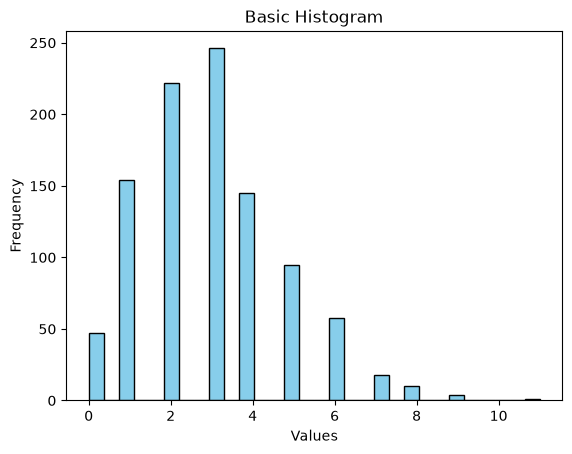

In [90]:
plt.hist(df['zombies_killed'], bins=30, color='skyblue', edgecolor='black')

# Add labels and title
plt.title('Basic Histogram')
plt.xlabel('Values')
plt.ylabel('Frequency')

# Display the plot
plt.show()

In [91]:
df['major'].unique()

<StringArray>
[                     'medicine/nursing',
       'criminal justice administration',
                             'education',
                        'energy studies',
                             'logistics',
                            'psychology',
                                'botany',
                         'communication',
                     'military strategy',
                             'economics',
                'mechanical engineering',
                    'physical education',
                            'philosophy',
                               'biology',
                      'applied sciences',
                      'animal husbandry',
                 'agricultural sciences',
                     'culinart services',
                         'city planning',
 'integrated water resources management',
                          'pharmacology',
                 'environmental science',
                        'human services',
                    

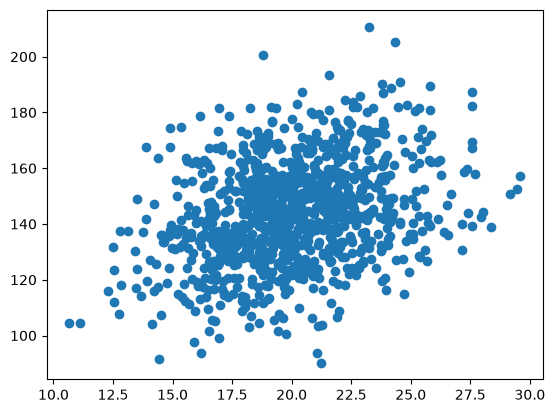

In [92]:
plt.scatter(df['age'], df['weight'])

In [93]:
df_hot_encoded = pd.get_dummies(df, columns=['major', 'gender'], dtype=int)
df_hot_encoded.head()

,id,first_name,last_name,height,weight,zombies_killed,years_of_education,age,major_agricultural sciences,major_animal husbandry,...,major_mechanical engineering,major_medicine/nursing,major_military strategy,major_pharmacology,major_philosophy,major_physical education,major_psychology,gender_Female,gender_Male,gender_NonBinary
0,1,Sarah,Little,62.889507,132.087165,2,1,17.642745,0,0,...,0,1,0,0,0,0,0,1,0,0
1,2,Mark,Duncan,67.802766,146.375293,5,3,22.589513,0,0,...,0,0,0,0,0,0,0,0,1,0
2,3,Brandon,Perez,72.129085,152.937022,1,1,21.912760,0,0,...,0,0,0,0,0,0,0,0,1,0
3,4,Roger,Coleman,66.784840,129.741805,5,6,18.190582,0,0,...,0,0,0,0,0,0,0,0,1,0
4,5,Tammy,Powell,64.718320,132.426492,4,3,21.103986,0,0,...,0,0,0,0,0,0,0,1,0,0


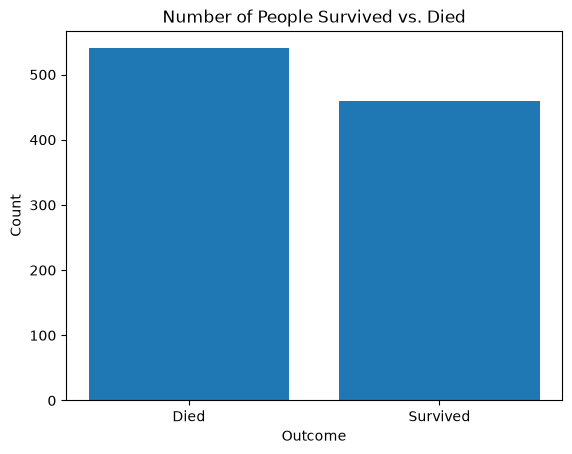

In [149]:
# 2. Calculate BMI
bmi = (df_hot_encoded['weight'] / (df_hot_encoded['height'] ** 2)) * 703

# 3. Assign survival modifiers to specific majors
# High-utility apocalypse majors get strong positive boosts; less practical ones get neutral/slight penalties
major_boost = (
    1.5 * df_hot_encoded['major_military strategy']
    + 1.3 * df_hot_encoded['major_medicine/nursing']
    + 1.1 * df_hot_encoded['major_mechanical engineering']
    + 0.9 * df_hot_encoded['major_agricultural sciences']
    + 0.8 * df_hot_encoded['major_pharmacology']
    + 0.6 * df_hot_encoded['major_physical education']
    - 0.4 * df_hot_encoded['major_philosophy']
    - 0.2 * df_hot_encoded['major_psychology']
)

# 4. Add a sharp interaction rule (great for Decision Trees to split on!)
# Example: Medical/pharma majors survive at much higher rates if they have >= 14 years of education (grad-level training)
med_specialist_bonus = np.where(
    ((df_hot_encoded['major_medicine/nursing'] == 1) | (df_hot_encoded['major_pharmacology'] == 1))
    & (df_hot_encoded['years_of_education'] >= 14),
    1.2,
    0.0
)

# 5. Combine everything into the final logit equation
logit = (
    0.65 * df_hot_encoded['zombies_killed']
    + 0.12 * df_hot_encoded['years_of_education']
    - 0.05 * np.abs(df_hot_encoded['age'] - 28)
    - 0.08 * np.abs(bmi - 22)
    + major_boost
    + med_specialist_bonus
    - 2.2  # Intercept tuned to keep survived roughly balanced (~50/50)
)

# 6. Generate binary survival target
prob = 1 / (1 + np.exp(-logit))
np.random.seed(42)
df_hot_encoded['survived'] = np.random.binomial(1, prob)

import matplotlib.pyplot as plt

# Sort by index so 0 (Died) is first and 1 (Survived) is second
survival_counts = df_hot_encoded['survived'].value_counts().sort_index()

plt.bar(survival_counts.index, survival_counts.values)

# Replace the x-axis tick positions with custom labels
plt.xticks([0, 1], ['Died', 'Survived'])

plt.xlabel('Outcome')
plt.ylabel('Count')
plt.title('Number of People Survived vs. Died')
plt.show()

In [95]:
X = df_hot_encoded.drop(['survived', 'first_name', 'last_name', 'id'], axis=1)
y = df_hot_encoded['survived']

X_train, X_test, y_train, y_test = train_test_split(X,y) 

In [96]:
print(X.columns)
print(y.unique())

Index(['height', 'weight', 'zombies_killed', 'years_of_education', 'age',
       'major_agricultural sciences', 'major_animal husbandry',
       'major_applied sciences', 'major_architecture', 'major_biology',
       'major_botany', 'major_business administration', 'major_city planning',
       'major_communication', 'major_criminal justice administration',
       'major_culinart services', 'major_economics', 'major_education',
       'major_energy studies', 'major_environmental science',
       'major_epidemiology', 'major_human services',
       'major_integrated water resources management', 'major_logistics',
       'major_mechanical engineering', 'major_medicine/nursing',
       'major_military strategy', 'major_pharmacology', 'major_philosophy',
       'major_physical education', 'major_psychology', 'gender_Female',
       'gender_Male', 'gender_NonBinary'],
      dtype='str')
[0 1]


In [97]:
scaler = StandardScaler()

scaler.fit(X_train)

X_train = scaler.transform(X_train)
X_test = scaler.transform(X_test)

X_train


array([[ 2.83273986e-01,  2.51738689e-02,  2.23849408e+00, ...,
        -9.84125976e-01, -9.78889444e-01,  7.25061574e+00],
       [ 6.19516124e-01, -7.64335381e-01,  5.60742021e-01, ...,
         1.01613007e+00, -9.78889444e-01, -1.37919321e-01],
       [ 9.32526788e-01,  7.56713231e-01,  1.11999271e+00, ...,
        -9.84125976e-01,  1.02156582e+00, -1.37919321e-01],
       ...,
       [-1.29783811e+00, -1.36481178e+00, -5.57759351e-01, ...,
         1.01613007e+00, -9.78889444e-01, -1.37919321e-01],
       [ 8.99191122e-01,  7.03373369e-01,  5.60742021e-01, ...,
        -9.84125976e-01,  1.02156582e+00, -1.37919321e-01],
       [ 1.69343880e-01, -1.64379620e-01,  1.49133516e-03, ...,
         1.01613007e+00, -9.78889444e-01, -1.37919321e-01]],
      shape=(750, 34))

## Neural Net Version 1

In [ ]:
mlp_1 = MLPClassifier(hidden_layer_sizes=(10,10,15), max_iter=5000)

In [126]:
mlp_1.fit(X_train, y_train)

,"hidden_layer_sizes hidden_layer_sizes: array-like of shape(n_layers - 2,), default=(100,)The ith element represents the number of neurons in the ithhidden layer.","(10, ...)"
,"max_iter max_iter: int, default=200Maximum number of iterations. The solver iterates until convergence(determined by 'tol') or this number of iterations. For stochasticsolvers ('sgd', 'adam'), note that this determines the number of epochs(how many times each data point will be used), not the number ofgradient steps.",5000
,"activation activation: {'identity', 'logistic', 'tanh', 'relu'}, default='relu'Activation function for the hidden layer.- 'identity', no-op activation, useful to implement linear bottleneck, returns f(x) = x- 'logistic', the logistic sigmoid function, returns f(x) = 1 / (1 + exp(-x)).- 'tanh', the hyperbolic tan function, returns f(x) = tanh(x).- 'relu', the rectified linear unit function, returns f(x) = max(0, x)",'relu'
,"solver solver: {'lbfgs', 'sgd', 'adam'}, default='adam'The solver for weight optimization.- 'lbfgs' is an optimizer in the family of quasi-Newton methods.- 'sgd' refers to stochastic gradient descent.- 'adam' refers to a stochastic gradient-based optimizer proposed by Kingma, Diederik, and Jimmy BaFor a comparison between Adam optimizer and SGD, see:ref:`sphx_glr_auto_examples_neural_networks_plot_mlp_training_curves.py`.Note: The default solver 'adam' works pretty well on relativelylarge datasets (with thousands of training samples or more) in terms ofboth training time and validation score.For small datasets, however, 'lbfgs' can converge faster and performbetter.",'adam'
,"alpha alpha: float, default=0.0001Strength of the L2 regularization term. The L2 regularization termis divided by the sample size when added to the loss.For an example usage and visualization of varying regularization, see:ref:`sphx_glr_auto_examples_neural_networks_plot_mlp_alpha.py`.",0.0001
,"batch_size batch_size: int, default='auto'Size of minibatches for stochastic optimizers.If the solver is 'lbfgs', the classifier will not use minibatch.When set to ""auto"", `batch_size=min(200, n_samples)`.",'auto'
,"learning_rate learning_rate: {'constant', 'invscaling', 'adaptive'}, default='constant'Learning rate schedule for weight updates.- 'constant' is a constant learning rate given by 'learning_rate_init'.- 'invscaling' gradually decreases the learning rate at each time step 't' using an inverse scaling exponent of 'power_t'. effective_learning_rate = learning_rate_init / pow(t, power_t)- 'adaptive' keeps the learning rate constant to 'learning_rate_init' as long as training loss keeps decreasing. Each time two consecutive epochs fail to decrease training loss by at least tol, or fail to increase validation score by at least tol if 'early_stopping' is on, the current learning rate is divided by 5.Only used when ``solver='sgd'``.",'constant'
,"learning_rate_init learning_rate_init: float, default=0.001The initial learning rate used. It controls the step-sizein updating the weights. Only used when solver='sgd' or 'adam'.",0.001
,"power_t power_t: float, default=0.5The exponent for inverse scaling learning rate.It is used in updating effective learning rate when the learning_rateis set to 'invscaling'. Only used when solver='sgd'.",0.5
,"shuffle shuffle: bool, default=TrueWhether to shuffle samples in each iteration. Only used whensolver='sgd' or 'adam'.",True
,"random_state random_state: int, RandomState instance, default=NoneDetermines random number generation for weights and biasinitialization, train-test split if early stopping is used, and batchsampling when solver='sgd' or 'adam'.Pass an int for reproducible results across multiple function calls.See :term:`Glossary <random_state>`.",None


In [127]:
predictions_1 = mlp_1.predict(X_test)

In [128]:
print(confusion_matrix(y_test, predictions_1))

[[90 48]
 [44 68]]


In [129]:
print(classification_report(y_test, predictions_1))

              precision    recall  f1-score   support

           0       0.67      0.65      0.66       138
           1       0.59      0.61      0.60       112

    accuracy                           0.63       250
   macro avg       0.63      0.63      0.63       250
weighted avg       0.63      0.63      0.63       250



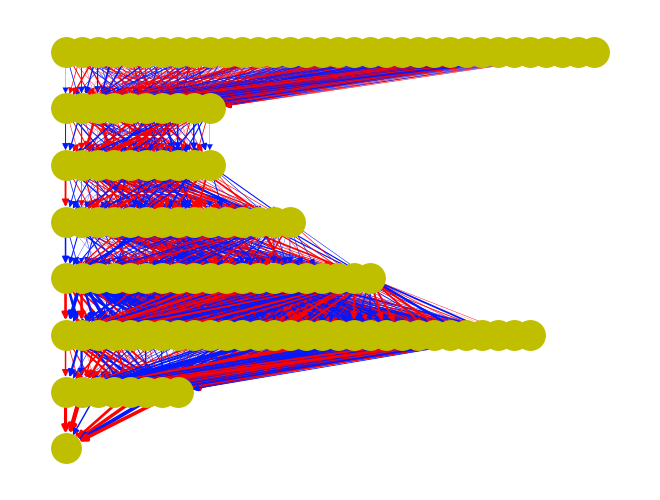

In [103]:
import networkx as nx
import colorsys

def show_ann(mlp):
    hidden_layers_n = len(mlp.coefs_)-1
    layers_n = hidden_layers_n + 2
    input_neurons_n = len(mlp.coefs_[0])
    hidden_neurons_n = [len(mlp.coefs_[i+1]) for i in range(hidden_layers_n)]
    output_neurons_n = len(mlp.coefs_[-1][0])

    G = nx.DiGraph()
    pos = {}

    # Create the neurons of the input layer
    for i in range(input_neurons_n):
        pos['Layer0_{}'.format(i)] = (i,layers_n-1)

    for j in range(hidden_layers_n):
        # Create the neurons of the j'th hidden layer
        prev_layer = j
        cur_layer = j+1
        if (j == 0):
            prev_size = input_neurons_n
        else:
            prev_size = hidden_neurons_n[j-1]
        for i in range(hidden_neurons_n[j]):
            pos['Layer{}_{}'.format(cur_layer,i)] = (i,layers_n-1-cur_layer)
            for k in range(prev_size):
                w = mlp.coefs_[prev_layer][k][i]
                G.add_edge('Layer{}_{}'.format(prev_layer,k),'Layer{}_{}'.format(cur_layer,i), weight=w)

    # Create the neurons of the output layer
    prev_layer = hidden_layers_n
    cur_layer = hidden_layers_n+1
    for i in range(output_neurons_n):
        pos['Layer{}_{}'.format(cur_layer,i)] = (i,layers_n-1-cur_layer)
        for k in range(hidden_neurons_n[-1]):
            w = mlp.coefs_[prev_layer][k][i]
            G.add_edge('Layer{}_{}'.format(prev_layer,k),'Layer{}_{}'.format(cur_layer,i), weight=w)

    edges = G.edges()
    colors = [colorsys.hsv_to_rgb(0 if G[u][v]['weight'] < 0 else 0.65,
                                  1,#min(1, abs(G[u][v]['weight'])),
                                  1) for u,v in edges]
    weights = [abs(G[u][v]['weight'])*2 for u,v in edges]

    nx.draw(G, pos, node_color='y', node_size=450, width=weights, edge_color=colors)
    
show_ann(mlp_1)

## Neural Networks Version 2

In [145]:
mlp_2 = MLPClassifier(hidden_layer_sizes=(12,14,15,10,10), max_iter=5000)
mlp_2.fit(X_train, y_train)
predictions_2 = mlp_2.predict(X_test)
print(confusion_matrix(y_test, predictions_2))
print(classification_report(y_test, predictions_2))

[[87 51]
 [50 62]]
              precision    recall  f1-score   support

           0       0.64      0.63      0.63       138
           1       0.55      0.55      0.55       112

    accuracy                           0.60       250
   macro avg       0.59      0.59      0.59       250
weighted avg       0.60      0.60      0.60       250



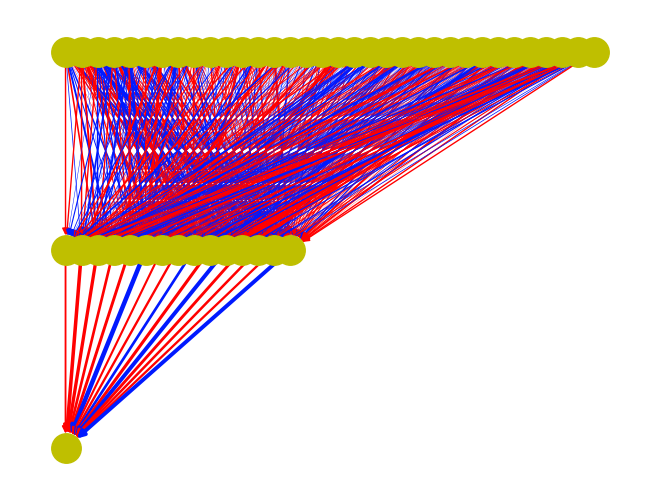

In [105]:
show_ann(mlp_2)

## Neural Networks Version 3

In [147]:
mlp_3 = MLPClassifier(hidden_layer_sizes=(4,5,5,4,6), max_iter=5000)
mlp_3.fit(X_train, y_train)
predictions_3 = mlp_3.predict(X_test)
print(confusion_matrix(y_test, predictions_3))
print(classification_report(y_test, predictions_3))

[[97 41]
 [57 55]]
              precision    recall  f1-score   support

           0       0.63      0.70      0.66       138
           1       0.57      0.49      0.53       112

    accuracy                           0.61       250
   macro avg       0.60      0.60      0.60       250
weighted avg       0.60      0.61      0.60       250



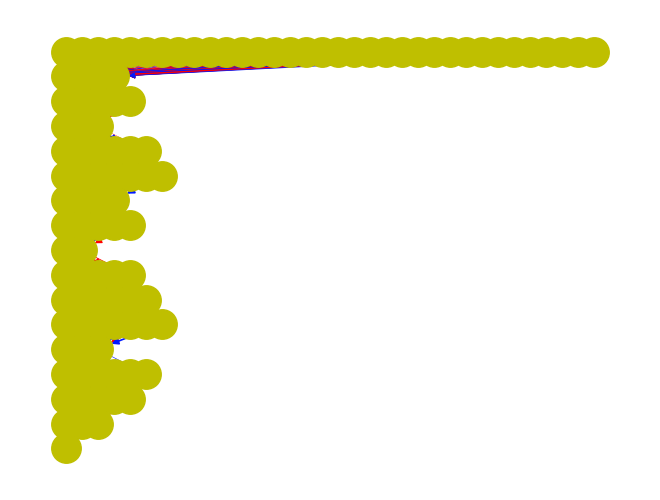

In [107]:

show_ann(mlp_3)

## Decision Tree

In [108]:
# For the decision trees you should visualize at least two trees (using code we saw in class) at different maximum depths.
# Discuss the effect the depth has on bias and variance.
# Discuss the choices the algorithm makes in which attributes to split on.
# For example, at a given tree level do all nodes split on the same attribute? Why or why not?

In [109]:
X = df_hot_encoded.drop(['survived', 'first_name', 'last_name', 'id'], axis=1)
y = df_hot_encoded['survived']

# X_train, X_test, y_train, y_test = train_test_split(X,y) 

### Decision Tree 1

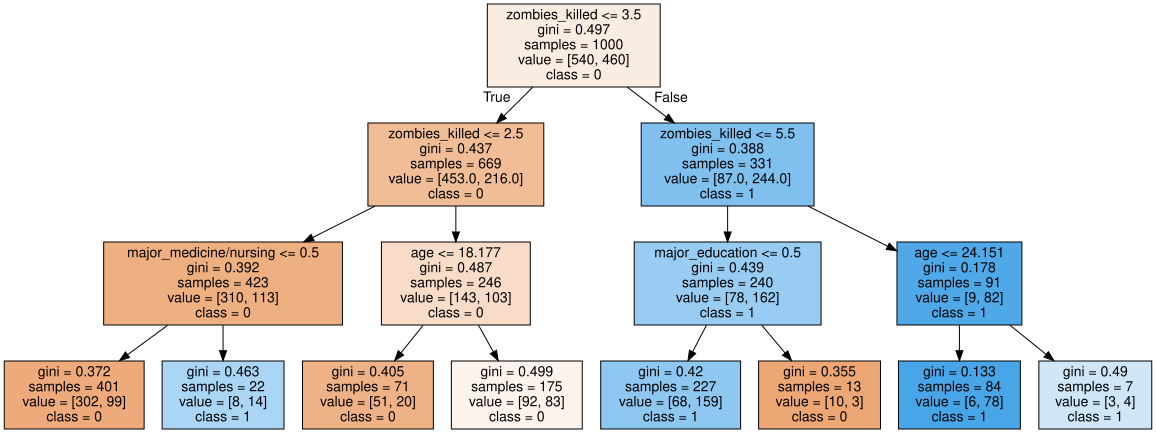

In [110]:
# fit a classification tree with max_depth=3 on all data
from sklearn.tree import DecisionTreeClassifier
from graphviz import Source
from sklearn import tree
from IPython.display import SVG


treeclf = DecisionTreeClassifier(max_depth=3, random_state=1)
treeclf.fit(X, y)

graph = Source(tree.export_graphviz(treeclf, out_file=None,
                                    feature_names=X.columns,
                                    class_names=['0', '1'], filled = True))
display(SVG(graph.pipe(format='svg')))

In [111]:
# compute the feature importances
pd.DataFrame({'feature':X.columns, 'importance':treeclf.feature_importances_})

,feature,importance
0,height,0.000000
1,weight,0.000000
2,zombies_killed,0.839823
3,years_of_education,0.000000
4,age,0.050399
5,major_agricultural sciences,0.000000
6,major_animal husbandry,0.000000
7,major_applied sciences,0.000000
8,major_architecture,0.000000
9,major_biology,0.000000


### Decision Tree 2

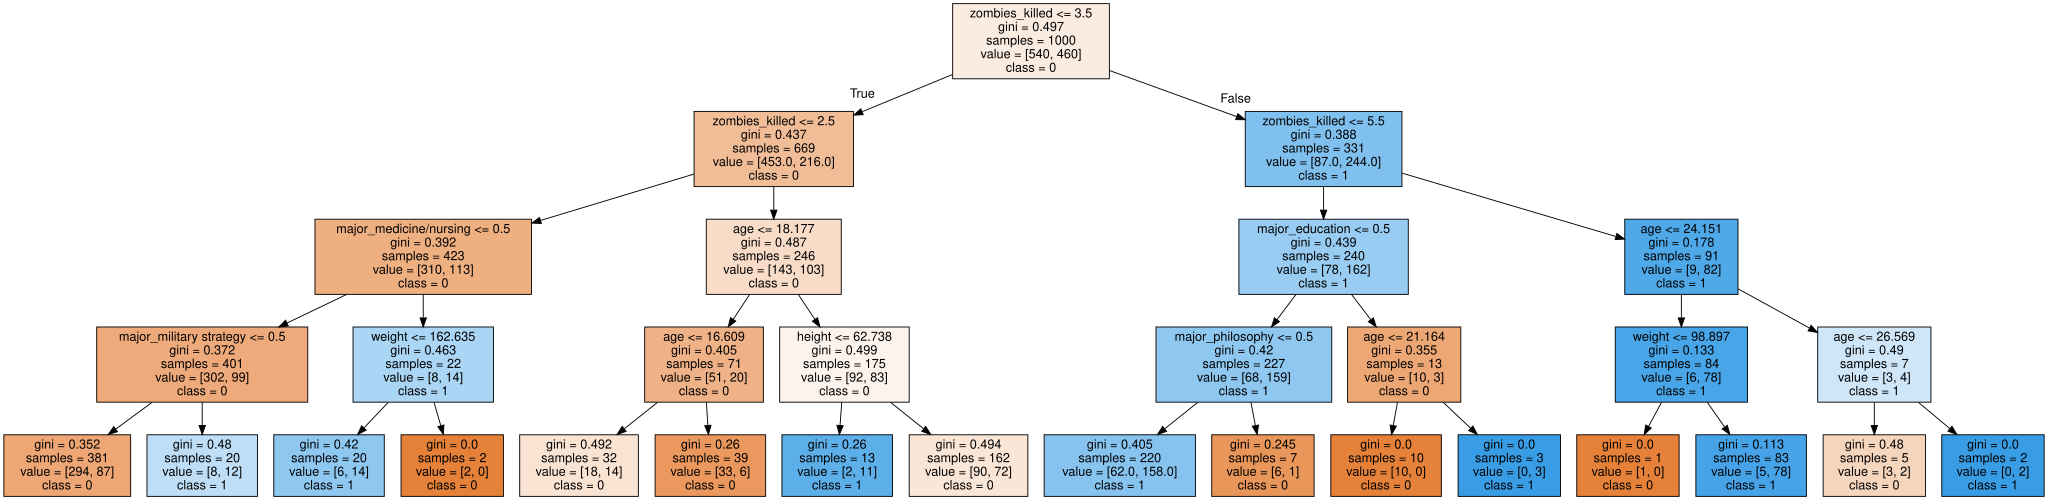

In [114]:
treeclf = DecisionTreeClassifier(max_depth=4, random_state=1)
treeclf.fit(X, y)

graph = Source(tree.export_graphviz(treeclf, out_file=None,
                                    feature_names=X.columns,
                                    class_names=['0', '1'], filled = True))
display(SVG(graph.pipe(format='svg')))

In [113]:
# compute the feature importances
pd.DataFrame({'feature':X.columns, 'importance':treeclf.feature_importances_})

,feature,importance
0,height,0.054179
1,weight,0.030799
2,zombies_killed,0.601421
3,years_of_education,0.000000
4,age,0.120327
5,major_agricultural sciences,0.000000
6,major_animal husbandry,0.000000
7,major_applied sciences,0.000000
8,major_architecture,0.000000
9,major_biology,0.000000
